# Step 6: Gradient boosting models

LightGBM models for claim frequency and capped claim severity. They use the same test set, large-claim cap, loading, k method and metrics as the GLM in `03_glm.ipynb`, so the two can be compared directly.

- Frequency: Poisson objective, with `log(exposure)` as the starting score (an offset), so the model learns claims per policy-year
- Severity: Gamma objective on the average capped claim, weighted by number of claims, policies with claims only
- Tuning: Optuna on a 15% validation slice of train. The test set is used once, in Section 9

## 1. Setup

- Imports
- Database connection from `.env`, the same way as in `03_glm.ipynb`

In [16]:
# one-off: install into the notebook's own kernel environment (PoDS). Skips packages already installed
# %pip install --quiet optuna lightgbm

In [17]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, URL
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_poisson_deviance, mean_gamma_deviance
import lightgbm as lgb
import optuna

SEED = 42
print("lightgbm", lgb.__version__, "| optuna", optuna.__version__)

# load the credential
load_dotenv(".env", override=True)
# build database connection
url = URL.create(
    "mysql+pymysql",
    username=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
    host=os.environ["DB_HOST"],
    port=int(os.environ["DB_PORT"]),
    database=os.environ["DB_NAME"],
)
engine = create_engine(url)

lightgbm 4.7.0 | optuna 5.0.0


## 2. Load the Step 4 views

- Same three views as the GLM notebook: `model_features`, `severity_features`, `large_claim_loading`
- Check: 678,013 policies, 24,944 severity rows, loading about 654 per claim

In [18]:
features = pd.read_sql("SELECT * FROM model_features", engine)
sev = pd.read_sql("SELECT * FROM severity_features", engine)
lcl = pd.read_sql("SELECT * FROM large_claim_loading", engine)
loading = float(lcl.loc[0, "loading_per_claim"])

assert len(features) == 678_013 and len(sev) == 24_944
print(f"policies: {len(features):,}, severity rows: {len(sev):,}, "
      f"cap: {float(lcl.loc[0, 'cap']):,.0f}, loading per claim: {loading:,.0f}")

policies: 678,013, severity rows: 24,944, cap: 34,062, loading per claim: 654


## 3. Features and split

- Raw rating factors, no bands: the trees find their own cut points
- `area` is left out because it is a banded copy of density, the same as in the GLM
- Text factors become pandas categories with one fixed category list, so LightGBM codes them the same way in train, validation and test
- Validation slice: 15% of train policies, chosen at random. A policy's severity row goes to the same side as its frequency row
- Train and test are the fixed SQL split, the same as the GLM

In [19]:
NUM_FEATURES = ["veh_power", "veh_age", "driv_age", "bonus_malus", "log_density"]
CAT_FEATURES = ["veh_gas", "veh_brand", "region"]
FEATURES = NUM_FEATURES + CAT_FEATURES

# one category list per factor, taken from all policies and used for every frame
CATS = {c: sorted(features[c].unique()) for c in CAT_FEATURES}
for df in (features, sev):
    for c in CAT_FEATURES:
        df[c] = pd.Categorical(df[c], categories=CATS[c])

freq_train = features[features["split"] == "train"].reset_index(drop=True)
freq_test = features[features["split"] == "test"].reset_index(drop=True)
sev_train = sev[sev["split"] == "train"].reset_index(drop=True)
sev_test = sev[sev["split"] == "test"].reset_index(drop=True)

# 15% of train policies for early stopping and tuning
fit_ids, val_ids = train_test_split(freq_train["id_pol"], test_size=0.15, random_state=SEED)
fr_fit = freq_train[freq_train["id_pol"].isin(fit_ids)]
fr_val = freq_train[freq_train["id_pol"].isin(val_ids)]
sv_fit = sev_train[sev_train["id_pol"].isin(fit_ids)]
sv_val = sev_train[sev_train["id_pol"].isin(val_ids)]

# the slices should look alike: similar frequency and average capped claim
for name, d in [("freq fit", fr_fit), ("freq valid", fr_val), ("freq test", freq_test)]:
    print(f"{name:11s} policies {len(d):>7,}  exposure {d['exposure'].sum():>9,.0f}  "
          f"frequency {d['claim_nb'].sum() / d['exposure'].sum():.4f}")
for name, d in [("sev fit", sv_fit), ("sev valid", sv_val), ("sev test", sev_test)]:
    avg = (d["avg_claim_capped"] * d["n_claims"]).sum() / d["n_claims"].sum()
    print(f"{name:11s} policies {len(d):>7,}  claims {d['n_claims'].sum():>6,}  avg capped claim {avg:,.0f}")

freq fit    policies 460,822  exposure   243,774  frequency 0.0739
freq valid  policies  81,322  exposure    42,914  frequency 0.0754
freq test   policies 135,869  exposure    71,672  frequency 0.0719
sev fit     policies  17,002  claims 18,048  avg capped claim 1,668
sev valid   policies   3,066  claims  3,239  avg capped claim 1,821
sev test    policies   4,876  claims  5,157  avg capped claim 1,687


## 4. Metric functions

Copied unchanged from Section 7 and 8 of `03_glm.ipynb`, so both models are scored the same way.

- `freq_deviance`: mean Poisson deviance of claims per year, weighted by exposure (lower = better)
- `sev_deviance`: mean Gamma deviance of the average capped claim, weighted by claim count (lower = better)
- `gini`: how well the predicted pure premium ranks actual capped cost (higher = better)
- `capped_cost`: actual capped claim cost per policy, 0 for policies without a claim

In [20]:
def freq_deviance(claims, exposure, pred_rate):
    # Poisson deviance of claims per year, weighted by exposure
    return mean_poisson_deviance(claims / exposure, pred_rate, sample_weight=exposure)

def sev_deviance(avg_claim, n_claims, pred_sev):
    # Gamma deviance of the average claim, weighted by the number of claims it averages
    return mean_gamma_deviance(avg_claim, pred_sev, sample_weight=n_claims)

def gini(actual_cost, pred_pp, exposure):
    # Lorenz curve: policies from lowest to highest predicted pure premium,
    # cumulative share of exposure (x) against cumulative share of actual cost (y)
    actual_cost, pred_pp, exposure = map(np.asarray, (actual_cost, pred_pp, exposure))
    order = np.argsort(pred_pp, kind="stable")
    x = np.concatenate([[0], np.cumsum(exposure[order])]) / exposure.sum()
    y = np.concatenate([[0], np.cumsum(actual_cost[order])]) / actual_cost.sum()
    area = np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2)
    return 1 - 2 * area   # 0 = no better than random, higher = better ranking

# actual capped claim cost per policy, 0 for policies without a claim row
def capped_cost(policies, sev_rows):
    cost = (sev_rows["avg_claim_capped"] * sev_rows["n_claims"]).set_axis(sev_rows["id_pol"])
    return policies["id_pol"].map(cost).fillna(0).to_numpy()

## 5. Frequency GBM: first fit

- A first fit with the plan's starting settings, to check the setup works and get a score to beat
- `init_score = log(exposure)` is the offset: each tree adds to it, so the model learns log(claims per year) and exposure keeps a fixed coefficient of 1
- The validation set has its own `init_score`, so early stopping scores it with the exposure included
- `predict()` ignores `init_score`, so its output is claims per policy-year (the rate), which is what `freq_deviance` expects

In [21]:
def freq_data(df, reference=None):
    # label = claim count; init_score = log(exposure), the offset
    return lgb.Dataset(df[FEATURES], label=df["claim_nb"],
                       init_score=np.log(df["exposure"]), reference=reference)

FREQ_BASE = {"objective": "poisson", "verbose": -1, "seed": SEED}
start = {"learning_rate": 0.05, "num_leaves": 31, "min_data_in_leaf": 500}

d_fit = freq_data(fr_fit)
d_val = freq_data(fr_val, reference=d_fit)
freq_start = lgb.train({**FREQ_BASE, **start}, d_fit, num_boost_round=3000, valid_sets=[d_val],
                       callbacks=[lgb.early_stopping(100, verbose=False)])
val_rate = freq_start.predict(fr_val[FEATURES], num_iteration=freq_start.best_iteration)

# context: a flat rate (every policy gets the fit-set average frequency)
flat_rate = fr_fit["claim_nb"].sum() / fr_fit["exposure"].sum()
flat_dev = freq_deviance(fr_val["claim_nb"], fr_val["exposure"], np.full(len(fr_val), flat_rate))
start_dev = freq_deviance(fr_val["claim_nb"], fr_val["exposure"], val_rate)
print(f"rounds: {freq_start.best_iteration}")
print(f"validation deviance: {start_dev:.4f} (flat rate {flat_dev:.4f}, {1 - start_dev / flat_dev:.1%} lower)")

# with the offset, predicted claims should add up close to actual claims
print(f"validation claims: actual {fr_val['claim_nb'].sum():,}, predicted {(val_rate * fr_val['exposure']).sum():,.0f}")

rounds: 432
validation deviance: 0.4552 (flat rate 0.4847, 6.1% lower)
validation claims: actual 3,237, predicted 3,177


## 6. Tune the frequency GBM with Optuna

- 30 trials, each scored on validation Poisson deviance, with early stopping to pick the number of rounds
- Tuned: `learning_rate`, `num_leaves`, `min_data_in_leaf`, `feature_fraction`, `bagging_fraction`, `lambda_l2`
- `bagging_fraction` fits each tree on a random share of the rows (`bagging_freq = 1` resamples every round); 1.0 = off
- Trial 1 is the starting settings from Section 5, so tuning can only match or improve on them
- This is the slow cell: roughly 30 × the time Section 5 took. Lower `N_TRIALS_FREQ` for a quick test run

In [22]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS_FREQ = 30
MAX_ROUNDS = 3000
BAGGING = {"bagging_freq": 1}   # resample rows every round; does nothing while bagging_fraction = 1.0

def report(study, trial):
    # print progress every 10 trials
    if (trial.number + 1) % 10 == 0:
        print(f"trial {trial.number + 1}: best validation deviance so far {study.best_value:.5f}")

def freq_objective(trial):
    params = {
        **FREQ_BASE, **BAGGING,
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 128, log=True),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 20, 5000, log=True),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 100, log=True),
    }
    # new Datasets each trial: LightGBM fixes some settings (e.g. min_data_in_leaf filtering) when a Dataset is built
    d_fit = freq_data(fr_fit)
    d_val = freq_data(fr_val, reference=d_fit)
    model = lgb.train(params, d_fit, num_boost_round=MAX_ROUNDS, valid_sets=[d_val],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
    # best_iteration is 0 only if early stopping never triggered (still improving at MAX_ROUNDS)
    trial.set_user_attr("n_rounds", model.best_iteration or MAX_ROUNDS)
    rate = model.predict(fr_val[FEATURES], num_iteration=model.best_iteration)
    return freq_deviance(fr_val["claim_nb"], fr_val["exposure"], rate)

freq_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
freq_study.enqueue_trial({**start, "feature_fraction": 1.0, "bagging_fraction": 1.0, "lambda_l2": 1e-3})
freq_study.optimize(freq_objective, n_trials=N_TRIALS_FREQ, callbacks=[report])

FREQ_PARAMS = {**FREQ_BASE, **BAGGING, **freq_study.best_params}
FREQ_ROUNDS = freq_study.best_trial.user_attrs["n_rounds"]
print(f"\nbest validation deviance: {freq_study.best_value:.5f} "
      f"(start {start_dev:.5f}, {1 - freq_study.best_value / start_dev:.2%} lower)")
print("best settings:", freq_study.best_params, "| rounds:", FREQ_ROUNDS)

trial 10: best validation deviance so far 0.45503
trial 20: best validation deviance so far 0.45459
trial 30: best validation deviance so far 0.45452

best validation deviance: 0.45452 (start 0.45519, 0.15% lower)
best settings: {'learning_rate': 0.03223195501574444, 'num_leaves': 60, 'min_data_in_leaf': 44, 'feature_fraction': 0.7984876955727898, 'bagging_fraction': 0.5923267875076109, 'lambda_l2': 0.020036849120595054} | rounds: 516


In [23]:
# the 5 best trials: if they are spread across very different settings, the score is flat near the top
trials = freq_study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
top5 = trials.sort_values("value").head(5)
display(top5.round(5))
print(f"top-5 deviance spread: {top5['value'].max() - top5['value'].min():.5f} "
      "(under 0.0005 = flat: more trials would not help)")

# a top-5 setting sitting at the edge of its search range means the optimum may lie outside it:
# widen that range and rerun this section. feature_fraction / bagging_fraction at 1.0 and
# lambda_l2 at its floor just mean "off", so those edges are not flagged.
for p, dist in freq_study.best_trial.distributions.items():
    vals = top5[f"params_{p}"]
    if vals.min() <= dist.low * 1.25 and p != "lambda_l2":
        print(f"{p}: top-5 values go down to {vals.min():.4g}, near the floor {dist.low}: consider widening")
    if vals.max() >= dist.high * 0.8 and p not in ("feature_fraction", "bagging_fraction"):
        print(f"{p}: top-5 values go up to {vals.max():.4g}, near the ceiling {dist.high}: consider widening")

,number,value,params_bagging_fraction,params_feature_fraction,params_lambda_l2,params_learning_rate,params_min_data_in_leaf,params_num_leaves,user_attrs_n_rounds
25,25,0.45452,0.59233,0.79849,0.02004,0.03223,44,60,516
24,24,0.45454,0.71986,0.71247,0.00959,0.03482,55,54,414
28,28,0.45454,0.65974,0.65501,0.00201,0.02856,52,46,792
10,10,0.45459,0.65567,0.69647,0.03871,0.03449,39,50,494
19,19,0.45465,0.67905,0.63618,0.02980,0.04744,35,42,350


top-5 deviance spread: 0.00013 (under 0.0005 = flat: more trials would not help)
bagging_fraction: top-5 values go down to 0.5923, near the floor 0.5: consider widening


## 7. Severity GBM

- Gamma objective, label `avg_claim_capped`, weight `n_claims`, policies with claims only
- No offset: claim size does not depend on how long the policy ran
- Only about 17,000 policies to fit on, and severity is mostly noise (most GLM severity relativities were between 0.85 and 1.20), so the search allows only small, strongly regularised trees
- 30 trials (each takes seconds). The validation slice is small (about 3,000 policies), so the tuned score is noisy
- The Gamma GBM tends to under-predict total severity. k (Section 8) corrects the total

In [24]:
# a Gamma model needs every target above 0
assert (sev_train["avg_claim_capped"] > 0).all()
N_TRIALS_SEV = 30

def sev_data(df, reference=None):
    # weight = number of claims: an average over 3 claims is more reliable than 1 claim
    return lgb.Dataset(df[FEATURES], label=df["avg_claim_capped"], weight=df["n_claims"], reference=reference)

SEV_BASE = {"objective": "gamma", "verbose": -1, "seed": SEED}
sev_start = {"learning_rate": 0.03, "num_leaves": 8, "min_data_in_leaf": 300}

def sev_objective(trial):
    params = {
        **SEV_BASE, **BAGGING,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 32, log=True),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 50, 2000, log=True),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.5, 1.0),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.5, 1.0),
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 100, log=True),
    }
    d_fit = sev_data(sv_fit)
    d_val = sev_data(sv_val, reference=d_fit)
    model = lgb.train(params, d_fit, num_boost_round=MAX_ROUNDS, valid_sets=[d_val],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
    trial.set_user_attr("n_rounds", model.best_iteration or MAX_ROUNDS)
    pred = model.predict(sv_val[FEATURES], num_iteration=model.best_iteration)
    return sev_deviance(sv_val["avg_claim_capped"], sv_val["n_claims"], pred)

sev_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
sev_study.enqueue_trial({**sev_start, "feature_fraction": 1.0, "bagging_fraction": 1.0, "lambda_l2": 1e-3})
sev_study.optimize(sev_objective, n_trials=N_TRIALS_SEV, callbacks=[report])

SEV_PARAMS = {**SEV_BASE, **BAGGING, **sev_study.best_params}
SEV_ROUNDS = sev_study.best_trial.user_attrs["n_rounds"]

# context: every claim predicted at the fit-set average capped claim
flat_sev = (sv_fit["avg_claim_capped"] * sv_fit["n_claims"]).sum() / sv_fit["n_claims"].sum()
flat_sev_dev = sev_deviance(sv_val["avg_claim_capped"], sv_val["n_claims"], np.full(len(sv_val), flat_sev))
print(f"\nbest validation deviance: {sev_study.best_value:.5f} (flat average {flat_sev_dev:.5f})")
print("best settings:", sev_study.best_params, "| rounds:", SEV_ROUNDS)

trial 10: best validation deviance so far 1.21420
trial 20: best validation deviance so far 1.21420
trial 30: best validation deviance so far 1.21391

best validation deviance: 1.21391 (flat average 1.23248)
best settings: {'learning_rate': 0.011262956633121667, 'num_leaves': 6, 'min_data_in_leaf': 332, 'feature_fraction': 0.8313375882297063, 'bagging_fraction': 0.9984887113460744, 'lambda_l2': 0.004414207068052657} | rounds: 234


## 8. Final models and balance factor k

- Refit both models on all of train with the tuned settings and number of rounds
- k: the same method as the GLM. 5-fold cross-validation on train: refit both GBMs on 4 folds, predict the 5th
- k = actual capped cost ÷ predicted capped cost (frequency × severity × exposure), on the out-of-fold predictions
- k is calculated last, on the final tuned settings, because the Gamma GBM's shortfall changes with the number of rounds

In [25]:
def fit_freq_gbm(data):
    return lgb.train(FREQ_PARAMS, freq_data(data), num_boost_round=FREQ_ROUNDS)

def fit_sev_gbm(data):
    return lgb.train(SEV_PARAMS, sev_data(data), num_boost_round=SEV_ROUNDS)

actual_train = capped_cost(freq_train, sev_train)
oof_pred = np.zeros(len(freq_train))
fold_k = []

# 5-fold CV on train: each fold is predicted by models that never saw it
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
for fit_idx, val_idx in kf.split(freq_train):
    fit_pol, val_pol = freq_train.iloc[fit_idx], freq_train.iloc[val_idx]
    # a policy's severity row goes in the same fold as its frequency row
    sev_fit_rows = sev_train[sev_train["id_pol"].isin(fit_pol["id_pol"])]
    f_model, s_model = fit_freq_gbm(fit_pol), fit_sev_gbm(sev_fit_rows)
    # predicted capped cost = claims per year x exposure x cost per claim
    oof_pred[val_idx] = (f_model.predict(val_pol[FEATURES]) * val_pol["exposure"].to_numpy()
                         * s_model.predict(val_pol[FEATURES]))
    fold_k.append(actual_train[val_idx].sum() / oof_pred[val_idx].sum())

k = actual_train.sum() / oof_pred.sum()
print("k per fold:", np.round(fold_k, 4))
print(f"k = {k:.4f}")

# final models on all of train
freq_gbm = fit_freq_gbm(freq_train)
sev_gbm = fit_sev_gbm(sev_train)

k per fold: [1.0953 0.9536 0.989  1.0184 0.9991]
k = 1.0107


## 9. Test-set metrics

- Same metrics and the same pure premium formula as the GLM: frequency × (k × severity + loading per claim)
- Calibration is actual ÷ predicted capped cost, the same direction as k: above 1 = underpriced
- Compared against the GLM row in `models/results.csv`

In [26]:
# test-set predictions, one row per policy
test = freq_test[["id_pol", "exposure", "claim_nb"]].copy()
test["pred_freq"] = freq_gbm.predict(freq_test[FEATURES])
test["pred_sev"] = sev_gbm.predict(freq_test[FEATURES])
test["actual_capped"] = capped_cost(freq_test, sev_test)
test["pred_capped_pp"] = test["pred_freq"] * k * test["pred_sev"]            # per policy-year, after k
test["pure_premium"] = test["pred_freq"] * (k * test["pred_sev"] + loading)   # adds the large-claim loading

pred_cost = (test["pred_freq"] * test["exposure"] * test["pred_sev"]).sum()
metrics = {
    "freq_deviance": freq_deviance(test["claim_nb"], test["exposure"], test["pred_freq"]),
    "sev_deviance": sev_deviance(sev_test["avg_claim_capped"], sev_test["n_claims"], sev_gbm.predict(sev_test[FEATURES])),
    "gini": gini(test["actual_capped"], test["pred_capped_pp"], test["exposure"]),
    "k": k,
    # actual ÷ predicted, same direction as k and the decile chart: above 1 = underpriced
    "calib_before_k": test["actual_capped"].sum() / pred_cost,
    "calib_after_k": test["actual_capped"].sum() / (k * pred_cost),
}

# GLM row from 03_glm.ipynb
glm = pd.read_csv("models/results.csv").set_index("model").loc["GLM"]
comparison = pd.DataFrame({"GLM": glm[list(metrics)], "LightGBM": pd.Series(metrics)})
display(comparison.round(4))

# the CV numbers: improvement over the GLM
null_rate = freq_train["claim_nb"].sum() / freq_train["exposure"].sum()
null_dev = freq_deviance(test["claim_nb"], test["exposure"], np.full(len(test), null_rate))
print(f"frequency deviance: {1 - metrics['freq_deviance'] / glm['freq_deviance']:.1%} lower than the GLM "
      f"(flat rate {null_dev:.4f})")
print(f"severity deviance: {1 - metrics['sev_deviance'] / glm['sev_deviance']:.1%} lower than the GLM")
print(f"Gini: GLM {glm['gini']:.3f} -> LightGBM {metrics['gini']:.3f}")

,GLM,LightGBM
freq_deviance,0.4482,0.4395
sev_deviance,1.1553,1.1562
gini,0.3233,0.3656
k,1.0010,1.0107
calib_before_k,0.9683,0.9735
calib_after_k,0.9673,0.9632


frequency deviance: 1.9% lower than the GLM (flat rate 0.4706)
severity deviance: -0.1% lower than the GLM
Gini: GLM 0.323 -> LightGBM 0.366


## 10. Sanity checks

- Test-set actual vs predicted frequency by driver age and BonusMalus band (the GLM bands, used here only for display). Predicted should follow actual: high for young drivers and high BonusMalus
- Feature importance (share of total gain): which factors the trees split on most. SHAP in Step 7 explains this properly

In [27]:
check = freq_test.assign(
    pred_claims=test["pred_freq"].to_numpy() * freq_test["exposure"].to_numpy(),
    driv_age_band=pd.cut(freq_test["driv_age"], [17, 20, 25, 30, 40, 50, 65, 90],
                         labels=["18-20", "21-25", "26-30", "31-40", "41-50", "51-65", "66+"]),
    bm_band=pd.cut(freq_test["bonus_malus"], [49, 50, 60, 75, 100, 150],
                   labels=["50", "51-60", "61-75", "76-100", "101+"]),
)
for col in ["driv_age_band", "bm_band"]:
    g = check.groupby(col, observed=True).agg(
        exposure=("exposure", "sum"), claims=("claim_nb", "sum"), pred_claims=("pred_claims", "sum"))
    g["actual_freq"] = g["claims"] / g["exposure"]
    g["predicted_freq"] = g["pred_claims"] / g["exposure"]
    display(g[["exposure", "actual_freq", "predicted_freq"]].round(4))

importance = pd.DataFrame({
    "frequency": freq_gbm.feature_importance("gain"),
    "severity": sev_gbm.feature_importance("gain"),
}, index=FEATURES)
display((importance / importance.sum()).sort_values("frequency", ascending=False).round(3))

,exposure,actual_freq,predicted_freq
driv_age_band,,,
18-20,528.1366,0.2499,0.2424
21-25,2781.5756,0.1194,0.1336
26-30,5860.1978,0.0821,0.0842
31-40,16884.5980,0.0684,0.0699
41-50,17584.7776,0.0753,0.0749
51-65,19265.0876,0.0644,0.0683
66+,8767.3645,0.0553,0.0612


,exposure,actual_freq,predicted_freq
bm_band,,,
50,45021.3720,0.0497,0.0524
51-60,9603.0689,0.0740,0.0750
61-75,7299.8791,0.1090,0.1147
76-100,9024.3147,0.1270,0.1308
101+,723.1030,0.3596,0.3418


,frequency,severity
bonus_malus,0.406,0.072
driv_age,0.150,0.240
log_density,0.143,0.071
veh_age,0.090,0.112
region,0.086,0.372
veh_brand,0.057,0.091
veh_power,0.050,0.042
veh_gas,0.019,0.000


## 11. Decile calibration

- Same chart as the GLM: test policies sorted by predicted capped pure premium, cut into 10 equal-exposure groups
- Actual ÷ predicted for each group. k only fixes the total, so any group that is clearly off goes in the limitations
- Saved to `figures/gbm_decile_calibration.png`

,exposure,actual,predicted,actual_per_year,predicted_per_year,actual_over_predicted
decile,,,,,,
1,7167.080,378272.09,335002.354,52.779,46.742,1.129
2,7166.374,370907.71,445889.396,51.757,62.220,0.832
3,7167.666,393942.47,518596.546,54.961,72.352,0.760
4,7167.393,516036.98,584118.291,71.998,81.497,0.883
5,7167.065,681975.80,652469.522,95.154,91.037,1.045
6,7166.668,663514.95,733212.143,92.583,102.309,0.905
7,7167.556,727793.68,839603.929,101.540,117.140,0.867
8,7166.639,936074.14,997652.698,130.616,139.208,0.938
9,7167.381,1297874.81,1288777.377,181.081,179.811,1.007


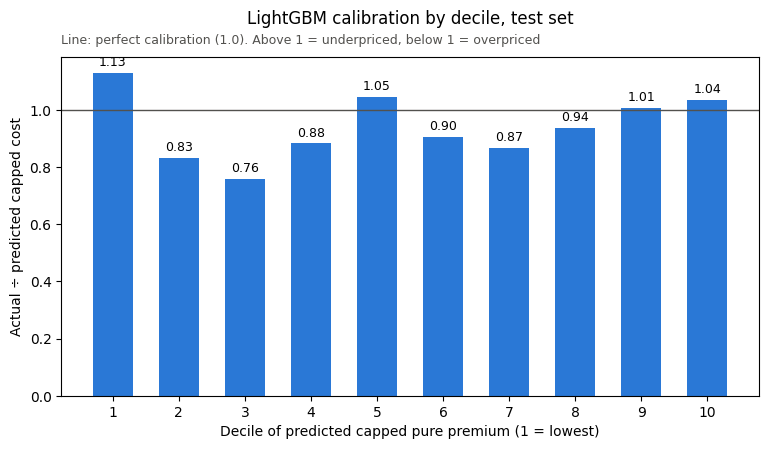

In [28]:
# same colors as 02_eda.ipynb
BLUE, INK_2 = "#2a78d6", "#52514e"

# 10 groups of equal exposure, from lowest to highest predicted capped pure premium
d = test.sort_values("pred_capped_pp")
cum_share = d["exposure"].cumsum() / d["exposure"].sum()
d["decile"] = np.ceil(cum_share * 10).clip(1, 10).astype(int)
dec = d.assign(pred_cost=d["pred_capped_pp"] * d["exposure"]).groupby("decile").agg(
    exposure=("exposure", "sum"), actual=("actual_capped", "sum"), predicted=("pred_cost", "sum"))
dec["actual_per_year"] = dec["actual"] / dec["exposure"]
dec["predicted_per_year"] = dec["predicted"] / dec["exposure"]
dec["actual_over_predicted"] = dec["actual"] / dec["predicted"]
display(dec.round(3))

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bar(dec.index, dec["actual_over_predicted"], width=0.6, color=BLUE)
ax.axhline(1, color=INK_2, linewidth=1)
for x, v in zip(dec.index, dec["actual_over_predicted"]):
    ax.annotate(f"{v:.2f}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.set_xticks(dec.index)
ax.set_xlabel("Decile of predicted capped pure premium (1 = lowest)")
ax.set_ylabel("Actual ÷ predicted capped cost")
ax.set_title("LightGBM calibration by decile, test set", pad=24)
ax.text(0, 1.04, "Line: perfect calibration (1.0). Above 1 = underpriced, below 1 = overpriced",
        transform=ax.transAxes, color=INK_2, fontsize=9)
fig.savefig("figures/gbm_decile_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Results and saved models

- Add the LightGBM row to `models/results.csv`, next to the GLM row. Re-running replaces the row instead of adding a copy
- Save per-policy test predictions for the Step 7 GLM-vs-GBM comparison (double lift)
- Save both models, the tuned settings, k and the loading, for Step 7 and the Streamlit app

In [29]:
results = pd.read_csv("models/results.csv")
results = results[results["model"] != "LightGBM"]
results = pd.concat([results, pd.DataFrame([{"model": "LightGBM", **metrics}])], ignore_index=True)
results.to_csv("models/results.csv", index=False)
display(results.round(4))

# per-policy test predictions, keyed by id_pol, same columns as glm_test_predictions.csv
test[["id_pol", "pred_freq", "pred_sev", "pure_premium"]].to_csv("models/gbm_test_predictions.csv", index=False)

# models as LightGBM text files; settings, k and loading as JSON
freq_gbm.save_model("models/gbm_freq.txt")
sev_gbm.save_model("models/gbm_sev.txt")
with open("models/gbm_params.json", "w") as f:
    json.dump({"features": FEATURES, "categories": CATS,
               "freq_params": FREQ_PARAMS, "freq_rounds": FREQ_ROUNDS,
               "sev_params": SEV_PARAMS, "sev_rounds": SEV_ROUNDS,
               "k": float(k), "loading_per_claim": loading}, f, indent=2)

,model,freq_deviance,sev_deviance,gini,k,calib_before_k,calib_after_k
0,GLM,0.4482,1.1553,0.3233,1.0010,0.9683,0.9673
1,LightGBM,0.4395,1.1562,0.3656,1.0107,0.9735,0.9632


**Conclusion.**

The LightGBM frequency-severity model beats the GLM on the same test set and is the pricing model from here on. The GLM stays as the benchmark for the Step 7 comparison.

- **Frequency:** Poisson deviance 0.4395 vs 0.4482 for the GLM, 1.9% lower. Against the flat rate (0.4706) the GLM explains 4.8% of the deviance and the GBM 6.6%, about 40% more of the part any model can explain. The rest is chance: over 95% of policies have no claim.
- **Ranking:** Gini 0.366 vs 0.323 (+13%). Actual cost per policy-year runs from 53 in the cheapest decile to 381 in the most expensive (7.2×); the GLM's range was 57 to 318 (5.6×). This is the gain that matters for pricing.
- **Severity:** a tie (1.1562 vs 1.1553). Claim size is mostly noise and the GBM finds nothing the GLM misses. The validation slice has only about 3,000 policies, so severity tuning is noisy: this run's best validation score was slightly worse than an earlier run's, yet test was better.
- **Tuning:** the surface is flat. 30 Optuna trials improved on the plan's starting settings by 0.15%, and the top 5 trials are within 0.00013 of each other. The frequency model is as good as these 8 rating factors allow; more trials, a lower learning rate or a different library would not change the result.
- **What the trees use:** BonusMalus carries 41% of the frequency gain, driver age 15%, density 14%. For severity, region (37%) and driver age (24%) lead. Predicted frequency tracks actual across every age and BonusMalus band; the thin top bands are shrunk slightly toward the middle (101+: 0.342 predicted vs 0.360 actual).
- **Calibration:** k = 1.011 (the Gamma GBM under-predicts train cost by 1.1%). On test both models overprice by about 3% (0.974 before k, 0.963 after), the same gap as the GLM, so it is the test sample, not the model. Deciles swing from 0.76 (decile 3) to 1.13 (decile 1), the same size as the GLM's swings: k fixes the total, not the shape. This goes in the limitations.
- **Not done, and why:** XGBoost would give the same answer with `base_margin` as the offset. A lower learning rate on the final refit would cost 2-4× the Section 8 time for about 0.1% of deviance. `bagging_fraction` sits near its search floor (0.59), but with a flat surface there is nothing below 0.5 worth another run.

Saved: `models/gbm_freq.txt`, `models/gbm_sev.txt`, `models/gbm_params.json`, `models/gbm_test_predictions.csv`, and the LightGBM row in `models/results.csv`.